In [1]:
import numpy as np
import matplotlib.pyplot as plt
n_pts = 100
np.random.seed(42)
X = np.random.rand(100 , 2)


y = np.where((X[:,0] + X[: , 1] - 1) > 0, 1, 0).reshape(-1 , 1)


print(y)

[[1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [0]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [0]
 [0]
 [1]
 [1]
 [1]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [0]
 [1]
 [1]
 [0]
 [1]
 [1]
 [0]
 [0]
 [0]
 [0]
 [0]
 [0]
 [1]
 [1]
 [0]
 [1]
 [0]
 [1]
 [0]
 [0]
 [1]
 [0]
 [1]
 [1]]


In [2]:
def initialisation(X):
    return (np.random.randn(X.shape[1] , 1) 
            , np.random.randn(1))

In [3]:
def model(X , w , w0):
    m = X.dot(w) + w0
    return 1/(1+np.exp(-m))

In [4]:
def loss(A, y):
    return 1 / len(y) * np.sum(-y * np.log(A) - (1 - y) * np.log(1 - A))

In [5]:
def update(A, X, y, W, W0, taux):
    W = W - taux / len(y) * np.dot(X.T, A - y)
    W0 = W0 - taux / len(y) * np.sum(A - y)
    return (W, W0)

In [14]:
def prediction(W, W0, X):
    A = model(X, W, W0)
    return A >= .5


def perceptron(X, y, taux=0.1, n_iter=100):
    w, w0 = initialisation(X)
    loss_history = []
    for i in range(n_iter):
        A = model(X, w, w0)

        current_loss = loss(A, y)
        loss_history.append(current_loss)

        w, w0 = update(A, X, y, w, w0, taux)

        if (i + 1) % 100 == 0:
            print(f"iteration {i + 1} | loss : {current_loss}")

    return w, w0, loss_history


w, w0, loss_history = perceptron(X, y, taux=4, n_iter=1000)

iteration 100 | loss : 0.1780061315029094
iteration 200 | loss : 0.13687354526317394
iteration 300 | loss : 0.11857831415358205
iteration 400 | loss : 0.10760833629462134
iteration 500 | loss : 0.10006254531807693
iteration 600 | loss : 0.09444034387954986
iteration 700 | loss : 0.09002601007050552
iteration 800 | loss : 0.08642939556653738
iteration 900 | loss : 0.08341734073520421
iteration 1000 | loss : 0.08084077420432914


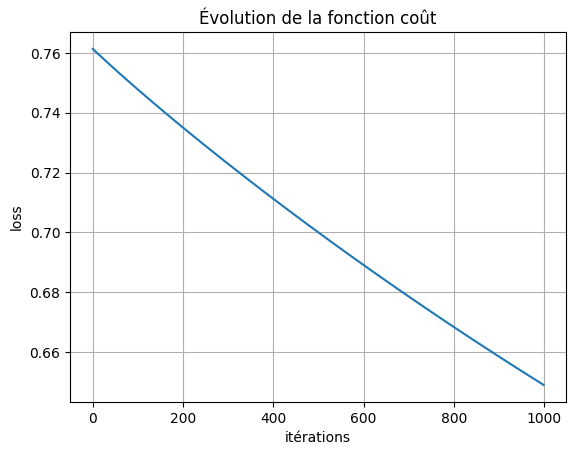

In [7]:
plt.plot(loss_history)
plt.xlabel("itérations")
plt.ylabel("loss")
plt.title("Évolution de la fonction coût")
plt.grid(True)
plt.show()

In [11]:
y_pred = prediction(w, w0, X)
score = np.mean(y_pred == y)

print("Score (accuracy) :", score)
print("Matrice de poids w :\n", w)
print("Biais w0 :", w0)

Score (accuracy) : 0.96
Matrice de poids w :
 [[10.75974283]
 [ 9.2234107 ]]
Biais w0 : [-10.19574203]


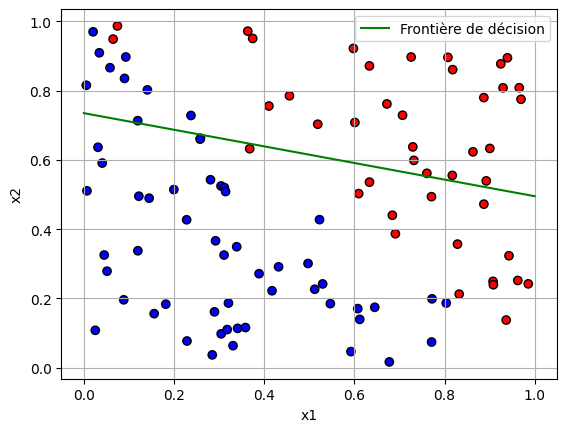

In [9]:
x1_vals = np.linspace(0, 1, 100)
x2_vals = -(w[0, 0] * x1_vals + w0[0]) / w[1, 0]

plt.scatter(X[:,0],X[:,1], c=y, cmap='bwr', edgecolors='k')
plt.plot(x1_vals, x2_vals, 'g-', label="Frontière de décision")

plt.xlabel("x1")
plt.ylabel("x2")
plt.legend()
plt.grid(True)
plt.show()